# Project AGAP: Household Flood Risk Classification for Santa Cruz, Laguna

**CSST 102 – Machine Learning Project Notebook (Weeks 1 to 3)**
CS 3-B · Group 9

*Project AGAP: AI-Based Flood Vulnerability Assessment and Evacuation Prioritization System for Santa Cruz, Laguna*

| Part | Week | What it covers |
|---|---|---|
| 1 | Week 1 | Problem formulation, test cell, loading the dataset |
| 2 | Week 2 | Data inspection, target and features, cleaning, encoding and split plan |
| 3 | Week 3 | Preprocessing, grouped train/test split, baseline model, saved predictions |

**How to run in Google Colab**

1. Upload `AGAP_Colab_Data.zip` when the data cell asks for it, or put it in Google Drive and set `USE_GOOGLE_DRIVE = True`.
2. Choose **Runtime → Run all**. The full notebook takes about 10–15 minutes on a free Colab runtime, most of it in Part 3.
3. The last cell packs every output (predictions, metrics, confusion matrix, trained model) into `AGAP_outputs.zip` and downloads it.

---
# Part 1 · Week 1: Machine Learning Problem Formulation

### Problem
Flood risk in Santa Cruz, Laguna differs from one household to the next. Two houses in the same barangay can face very
different danger depending on how close they are to a waterway, how high the ground is, what the house is made of, and
whether children, elderly members or persons with disability live there. Official hazard maps show where floodwater goes,
but they do not describe the people who live there.

### Guiding question
*Given a household's location, terrain, the official flood hazard at its site, the rainfall during an event and its
household profile, can a model classify the household's flood risk as **Low**, **Medium** or **High**?*

### Objectives
1. Build a household-level dataset from official flood hazard maps, terrain layers and historical rainfall.
2. Train and evaluate a classifier that assigns a risk level to each household for a given rain event.
3. Use the trained model in a map-based tool that supports evacuation prioritization.

### ML task
Supervised **multi-class classification**. One record is one household during one rainfall event, and the output is
`RiskLevel` (Low / Medium / High). High-risk records are the minority, so the model is judged mainly by **macro F1** and
**recall on the High class**, not by overall accuracy.

### 1.1 Test cell

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("Test cell ran successfully.")

Python      : 3.14.3
pandas      : 3.0.1
numpy       : 2.4.4
scikit-learn: 1.8.0
matplotlib  : 3.11.0
Test cell ran successfully.


### 1.2 Get the data files
The dataset files are bundled in `AGAP_Colab_Data.zip` (about 10 MB). In Colab the cell below asks you to upload it,
or reads it from Google Drive if `USE_GOOGLE_DRIVE = True`. On a local computer it reads the project folder directly.

In [2]:
import os, zipfile

USE_GOOGLE_DRIVE = False                          # set to True if the zip is in Google Drive
DRIVE_ZIP = "/content/drive/MyDrive/AGAP/AGAP_Colab_Data.zip"
ZIP_NAME = "AGAP_Colab_Data.zip"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        zip_path = DRIVE_ZIP
    else:
        from google.colab import files
        zip_path = ZIP_NAME
        if not os.path.exists(ZIP_NAME):
            uploaded = files.upload()              # choose AGAP_Colab_Data.zip
            zip_path = next(iter(uploaded))        # works even if the browser renamed the file
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("data")
    DATA_DIR = "data"
elif os.path.exists(ZIP_NAME):
    with zipfile.ZipFile(ZIP_NAME) as z:
        z.extractall("data")
    DATA_DIR = "data"
else:
    DATA_DIR = os.path.join("..", "AGAP_NOAH_Dataset")   # local project folder

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("Data folder:", DATA_DIR)
print(sorted(f for f in os.listdir(DATA_DIR) if f.endswith(".csv")))

Data folder: data
['CS 3-B_Group_9_Dataset_CSST 101 & CSST 102.csv', 'agap_noah_dataset.csv', 'agap_noah_dataset_raw.csv', 'data_dictionary.csv', 'label_audit.csv']


### 1.3 Load the dataset
`keep_default_na=False` is important here. `"None"` is a real NOAH flood class (the house is outside every modelled flood
zone). Without this option pandas would read it as a missing value.

In [3]:
DATASET_FILE = "CS 3-B_Group_9_Dataset_CSST 101 & CSST 102.csv"
df = pd.read_csv(os.path.join(DATA_DIR, DATASET_FILE), keep_default_na=False)

print("Rows   :", f"{df.shape[0]:,}")
print("Columns:", df.shape[1], "(22 inputs + RiskLevel)")
df.head()

Rows   : 232,110
Columns: 23 (22 inputs + RiskLevel)


,Age,HousingMaterial,HouseMembers,ChildrenCount,ElderCount,PWDCount,ElevationMeters,SlopeDegrees,DistanceToWaterwayM,LocationType,...,FloodHazard25yr,FloodHazard100yr,HouseFloodHazard5yr,HouseFloodHazard25yr,HouseFloodHazard100yr,MGBFloodSusceptibility,Rainfall24hMm,Rainfall3DayMm,Rainfall7DayMm,RiskLevel
0,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,78.14,93.06,145.20,Medium
1,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,56.02,83.89,109.14,Low
2,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,26.08,49.67,68.62,Low
3,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,0.36,1.14,29.68,Low
4,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,34.95,58.39,72.25,Low


In [4]:
counts = df["RiskLevel"].value_counts().reindex(["Low", "Medium", "High"])
pd.DataFrame({"Records": counts, "Share (%)": (counts / len(df) * 100).round(1)})

,Records,Share (%)
RiskLevel,,
Low,156037,67.2
Medium,56564,24.4
High,19509,8.4


### 1.4 Dataset sources

| Variables | Source |
|---|---|
| Household (age, housing material, members, children, elderly, PWD) | Simulated household profiles (AGAP v1.0), placed on real building locations |
| Elevation, slope | Copernicus DEM, 30 m |
| Distance to waterway, location type | OpenStreetMap waterways |
| Land cover | ESA WorldCover 2021 |
| Past surface water | JRC Global Surface Water, 1984–2024 |
| NOAH flood hazard (barangay and house, 5/25/100-year rain) | Project NOAH flood hazard maps (ODC-ODbL) |
| MGB flood susceptibility | MGB Detailed Flood Susceptibility map |
| Rainfall (24 h, 3-day, 7-day) | NASA POWER daily rainfall, 1991–2025 |
| **RiskLevel (target)** | Documented rule: risk = flood hazard × household vulnerability |

The dataset has 232,110 records: 7,737 households in all 26 barangays, each paired with 30 historical rainfall events.
Because the label comes from a rule and the household details are simulated, model scores show how well that rule can be
learned. They are not a measure of real flood prediction.

---
# Part 2 · Week 2: Dataset Preparation and Feature Engineering

This part works on the **raw** version of the dataset (`agap_noah_dataset_raw.csv`), which still contains duplicates,
missing values and wrong labels, so that every cleaning step can be shown and checked.

### 2.1 Load the raw file
`na_values=[""]` treats only empty cells as missing, so the class `"None"` is kept.

In [5]:
raw = pd.read_csv(os.path.join(DATA_DIR, "agap_noah_dataset_raw.csv"), keep_default_na=False, na_values=[""])
print("Raw shape:", raw.shape)
raw.head(3)

Raw shape: (241200, 28)


,HouseholdID,Barangay,Latitude,Longitude,EventDate,Age,HousingMaterial,HouseMembers,ChildrenCount,ElderCount,...,FloodHazard25yr,FloodHazard100yr,HouseFloodHazard5yr,HouseFloodHazard25yr,HouseFloodHazard100yr,MGBFloodSusceptibility,Rainfall24hMm,Rainfall3DayMm,Rainfall7DayMm,RiskLevel
0,AGAP-SCL-00001,Gatid,14.268392,121.371677,1993-12-27,76.0,Concrete,6,2,3,...,Low,Low,None,None,None,Moderate,78.14,93.06,145.20,Medium
1,AGAP-SCL-00001,Gatid,14.268392,121.371677,1994-10-21,76.0,Concrete,6,2,3,...,Low,Low,None,None,None,Moderate,56.02,83.89,109.14,Low
2,AGAP-SCL-00001,Gatid,14.268392,121.371677,1995-02-02,76.0,Concrete,6,2,3,...,Low,Low,None,None,None,Moderate,26.08,49.67,68.62,Low


### 2.2 Data types

In [6]:
types = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique values": raw.nunique(),
    "example": raw.iloc[0],
})
print(raw.dtypes.astype(str).value_counts().to_string())
types

str        14
float64    10
int64       4


,dtype,unique values,example
HouseholdID,str,8000,AGAP-SCL-00001
Barangay,str,26,Gatid
Latitude,float64,7448,14.268392
Longitude,float64,7330,121.371677
EventDate,str,60,1993-12-27
Age,float64,73,76.0
HousingMaterial,str,3,Concrete
HouseMembers,int64,12,6
ChildrenCount,int64,8,2
ElderCount,int64,5,3


### 2.3 Missing values

In [7]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["% of rows"] = (missing["missing"] / len(raw) * 100).round(2)
missing

,missing,% of rows
Age,3619,1.5
HousingMaterial,2410,1.0
SlopeDegrees,1937,0.8


### 2.4 Duplicates

In [8]:
print("Exact duplicate rows                   :", f"{raw.duplicated().sum():,}")
print("Repeated (HouseholdID, EventDate) pairs:", f"{raw.duplicated(['HouseholdID', 'EventDate']).sum():,}")

Exact duplicate rows                   : 1,200
Repeated (HouseholdID, EventDate) pairs: 1,200


### 2.5 Target variable

,Records,Share (%)
RiskLevel,,
Low,161427,66.9
Medium,59359,24.6
High,20414,8.5


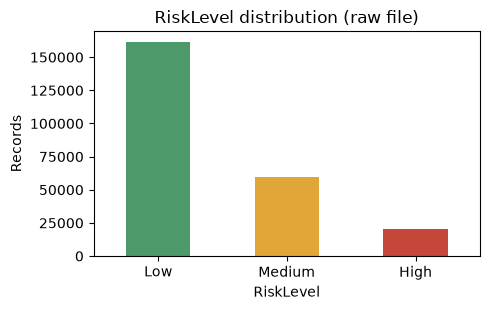

In [9]:
import matplotlib.pyplot as plt

LEVELS = ["Low", "Medium", "High"]
target_counts = raw["RiskLevel"].value_counts().reindex(LEVELS)
display(pd.DataFrame({"Records": target_counts, "Share (%)": (target_counts / len(raw) * 100).round(1)}))

ax = target_counts.plot.bar(color=["#4c9a6a", "#e0a63a", "#c4473a"], rot=0, figsize=(5, 3.2))
ax.set_title("RiskLevel distribution (raw file)")
ax.set_ylabel("Records")
plt.tight_layout()
plt.show()

The classes are imbalanced: High is fewer than one in ten records. A model that always answered "Low" would already be
about 67% accurate, which is why accuracy alone is not a fair measure here.

### 2.6 Target and candidate input features
Identifier columns are left out of the inputs. They describe *which* record it is, not *why* it is risky, and
`HouseholdID` or the coordinates would let the model memorize households. The values in `label_audit.csv` (risk
score, vulnerability score, event hazard) are also never used as inputs, because the label is calculated directly from
them.

In [10]:
TARGET = "RiskLevel"
ID_COLS = ["HouseholdID", "Barangay", "Latitude", "Longitude", "EventDate"]
FEATURE_GROUPS = {
    "Household": ["Age", "HousingMaterial", "HouseMembers", "ChildrenCount", "ElderCount", "PWDCount"],
    "Terrain at the house": ["ElevationMeters", "SlopeDegrees", "DistanceToWaterwayM", "LocationType",
                             "LandCoverType", "HistoricalWaterOccurrencePct"],
    "Flood hazard": ["FloodHazard5yr", "FloodHazard25yr", "FloodHazard100yr",
                     "HouseFloodHazard5yr", "HouseFloodHazard25yr", "HouseFloodHazard100yr",
                     "MGBFloodSusceptibility"],
    "Rainfall": ["Rainfall24hMm", "Rainfall3DayMm", "Rainfall7DayMm"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]
CATEGORICAL = [c for c in FEATURES if raw[c].dtype == object or str(raw[c].dtype) in ("string", "str", "category")]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

assert set(FEATURES) | set(ID_COLS) | {TARGET} == set(raw.columns)
print(f"{len(FEATURES)} candidate inputs: {len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical")
pd.DataFrame([(g, c, "categorical" if c in CATEGORICAL else "numeric")
              for g, cols in FEATURE_GROUPS.items() for c in cols],
             columns=["Group", "Feature", "Type"])

22 candidate inputs: 12 numeric, 10 categorical


,Group,Feature,Type
0,Household,Age,numeric
1,Household,HousingMaterial,categorical
2,Household,HouseMembers,numeric
3,Household,ChildrenCount,numeric
4,Household,ElderCount,numeric
5,Household,PWDCount,numeric
6,Terrain at the house,ElevationMeters,numeric
7,Terrain at the house,SlopeDegrees,numeric
8,Terrain at the house,DistanceToWaterwayM,numeric
9,Terrain at the house,LocationType,categorical


### 2.7 Numeric features

In [11]:
raw[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,237581.0,55.46,16.57,18.00,43.00,56.00,69.00,90.00
HouseMembers,241200.0,4.34,2.24,1.00,3.00,4.00,6.00,12.00
ChildrenCount,241200.0,0.99,1.06,0.00,0.00,1.00,2.00,7.00
ElderCount,241200.0,0.41,0.63,0.00,0.00,0.00,1.00,4.00
PWDCount,241200.0,0.12,0.35,0.00,0.00,0.00,0.00,3.00
ElevationMeters,241200.0,11.57,5.98,1.63,7.25,10.02,14.68,35.89
SlopeDegrees,239263.0,1.70,1.30,0.01,0.81,1.38,2.26,12.80
DistanceToWaterwayM,241200.0,293.67,208.72,0.00,123.69,256.32,408.04,1260.00
HistoricalWaterOccurrencePct,241200.0,0.07,1.54,0.00,0.00,0.00,0.00,64.00
Rainfall24hMm,241200.0,73.92,60.83,0.19,16.52,63.73,126.81,226.13


### 2.8 Categorical features

In [12]:
for c in CATEGORICAL:
    print(f"{c:24s}", raw[c].value_counts(dropna=False).to_dict())

HousingMaterial          {'Concrete': 96992, 'SemiConcrete': 94306, 'LightMaterials': 47492, nan: 2410}
LocationType             {'Inland': 102248, 'NearWaterway': 91494, 'Riverside': 47458}
LandCoverType            {'TreeCover': 118391, 'BuiltUp': 111602, 'Cropland': 5489, 'Grassland': 5177, 'BareSparseVegetation': 541}
FloodHazard5yr           {'Low': 215632, 'Medium': 18847, 'None': 5757, 'High': 964}
FloodHazard25yr          {'Low': 168473, 'Medium': 71763, 'High': 964}
FloodHazard100yr         {'Medium': 149275, 'Low': 85042, 'High': 6883}
HouseFloodHazard5yr      {'None': 180888, 'Low': 42003, 'Medium': 16353, 'High': 1956}


HouseFloodHazard25yr     {'None': 148571, 'Low': 54062, 'Medium': 33538, 'High': 5029}
HouseFloodHazard100yr    {'None': 126955, 'Low': 60212, 'Medium': 47830, 'High': 6203}
MGBFloodSusceptibility   {'NotMapped': 131458, 'Moderate': 79146, 'High': 30596}


### 2.9 Records per household
Each household appears once for every rainfall event. This affects how the data must be split (see 2.12).

In [13]:
per_household = raw.drop_duplicates().groupby("HouseholdID").size()
print("Households:", f"{per_household.size:,}")
print("Records per household:", per_household.value_counts().to_dict())

Households: 8,000
Records per household: {30: 8000}


### 2.10 Cleaning
| Step | Decision | Reason |
|---|---|---|
| 1 | Drop exact duplicate rows | They repeat a record that is already present |
| 2 | Remove households with any missing value, rather than impute | Household details feed the label, so an imputed value would describe a household that does not exist, and its label would no longer match its inputs |
| 3 | Recompute wrong labels from the documented rule (risk score cut-offs 15 and 40) | Some labels were changed to a neighbouring level; the rule gives the correct one |
| 4 | Restore `Age` to whole numbers | It became decimal only because of the missing values |

In [14]:
log = [("Raw file", len(raw), raw.HouseholdID.nunique())]

# Step 1: duplicates
step1 = raw.drop_duplicates().reset_index(drop=True)
log.append(("After removing duplicates", len(step1), step1.HouseholdID.nunique()))

# Step 2: households with missing values
incomplete = step1.loc[step1.isna().any(axis=1), "HouseholdID"].unique()
step2 = step1[~step1.HouseholdID.isin(incomplete)].reset_index(drop=True)
log.append(("After removing incomplete households", len(step2), step2.HouseholdID.nunique()))

# Step 3: recompute labels from the rule
audit = pd.read_csv(os.path.join(DATA_DIR, "label_audit.csv"), keep_default_na=False,
                    usecols=["HouseholdID", "EventDate", "RiskScore"])
step3 = step2.merge(audit, on=["HouseholdID", "EventDate"], how="left", validate="one_to_one")
assert step3.RiskScore.notna().all()
rule_label = pd.cut(step3.RiskScore, [-np.inf, 15, 40, np.inf], right=False, labels=LEVELS).astype(str)
labels_fixed = int((rule_label != step3.RiskLevel).sum())
step3["RiskLevel"] = rule_label
step3 = step3.drop(columns="RiskScore")

# Step 4: Age back to integer
step3["Age"] = step3["Age"].astype(int)
clean_nb = step3
log.append(("After correcting labels", len(clean_nb), clean_nb.HouseholdID.nunique()))

print(f"Incomplete households removed: {len(incomplete)}")
print(f"Labels corrected            : {labels_fixed:,}")
pd.DataFrame(log, columns=["Step", "Rows", "Households"])

Incomplete households removed: 263
Labels corrected            : 1,181


,Step,Rows,Households
0,Raw file,241200,8000
1,After removing duplicates,240000,8000
2,After removing incomplete households,232110,7737
3,After correcting labels,232110,7737


### 2.11 Check the result against the published clean file

In [15]:
published = pd.read_csv(os.path.join(DATA_DIR, "agap_noah_dataset.csv"), keep_default_na=False)
print("Same shape  :", clean_nb.shape == published.shape, clean_nb.shape)
print("Same columns:", list(clean_nb.columns) == list(published.columns))
print("Missing values left:", int(clean_nb.isna().sum().sum()))

same_inputs = (clean_nb.drop(columns=TARGET).astype(str) == published.drop(columns=TARGET).astype(str)).all().all()
label_match = (clean_nb[TARGET] == published[TARGET])
print("All input values identical:", bool(same_inputs))
print(f"Labels identical: {label_match.sum():,} of {len(label_match):,}")

diff = published.loc[~label_match, ["HouseholdID", "EventDate", TARGET]].merge(
    pd.read_csv(os.path.join(DATA_DIR, "label_audit.csv"), keep_default_na=False,
                usecols=["HouseholdID", "EventDate", "RiskScore"]), on=["HouseholdID", "EventDate"])
diff

Same shape  : True (232110, 28)
Same columns: True
Missing values left: 0


All input values identical: True
Labels identical: 232,109 of 232,110


,HouseholdID,EventDate,RiskLevel,RiskScore
0,AGAP-SCL-02548,2022-10-29,Medium,40.0


The notebook's cleaning reproduces the published clean file exactly, apart from the row(s) shown above. In that case the
audit file stores the risk score rounded to four decimals, so a score just under the High cut-off (40) is saved as
`40.0` and cannot be told apart from the boundary. The published file was labelled from the unrounded score, so it is the
one used for modelling in Part 3.

### 2.12 Encoding and splitting plan

**Encoding.** The 10 categorical inputs are converted to the pandas `category` type. Scikit-learn's
`HistGradientBoostingClassifier` handles categories natively (`categorical_features="from_dtype"`), so one-hot encoding
is not needed. Tree models are not affected by the scale of a feature, so no scaling is applied.

**Splitting.** Every household appears 30 times, once per rain event. A plain random split would put the same house in
both training and test sets, so the model would be tested on households it has already seen. The data is therefore
split **by household**:
* 80/20 hold-out split with `GroupShuffleSplit` (`random_state=42`)
* 5-fold cross-validation with `GroupKFold` as a second check

**Class imbalance.** Training uses `class_weight="balanced"`, so a mistake on a Medium or High record costs more than a
mistake on a Low record. Results are reported with macro F1 and per-class recall.

---
# Part 3 · Week 3: Initial Machine Learning Model Development

### 3.1 Preprocessing

In [16]:
data = published.copy()
X = data[FEATURES].copy()
y = data[TARGET]
groups = data["HouseholdID"]

for c in CATEGORICAL:
    X[c] = X[c].astype("category")

assert not set(ID_COLS) & set(X.columns), "identifier columns must not be inputs"
assert X.isna().sum().sum() == 0
print("X:", X.shape, "| y:", y.shape)
print("Categorical inputs:", CATEGORICAL)
X.dtypes.astype(str).value_counts()

X: (232110, 22) | y: (232110,)
Categorical inputs: ['HousingMaterial', 'LocationType', 'LandCoverType', 'FloodHazard5yr', 'FloodHazard25yr', 'FloodHazard100yr', 'HouseFloodHazard5yr', 'HouseFloodHazard25yr', 'HouseFloodHazard100yr', 'MGBFloodSusceptibility']


category    10
float64      7
int64        5
Name: count, dtype: int64

### 3.2 Train/test split (grouped by household)

In [17]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Training rows: {len(train_idx):,}  ({groups.iloc[train_idx].nunique():,} households)")
print(f"Test rows    : {len(test_idx):,}  ({groups.iloc[test_idx].nunique():,} households)")
print("Households in both sets:", len(overlap))

pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).reindex(LEVELS)

Training rows: 185,670  (6,189 households)
Test rows    : 46,440  (1,548 households)
Households in both sets: 0


,Train,Test
RiskLevel,,
Low,124490,31547
Medium,45399,11165
High,15781,3728


### 3.3 Baseline model
`HistGradientBoostingClassifier` was chosen as the baseline because it handles a mix of numeric and categorical inputs
without extra encoding, trains quickly on 185,000 rows, and supports class weights.

In [18]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier

def make_model(class_weight="balanced"):
    return HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=500,
                                          class_weight=class_weight, random_state=0)

start = time.time()
model = make_model().fit(X_train, y_train)
print(f"Trained in {time.time() - start:.0f} s, {model.n_iter_} boosting iterations")

Trained in 18 s, 488 boosting iterations


### 3.4 Evaluation on the test households

In [19]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, matthews_corrcoef, precision_recall_fscore_support,
                             ConfusionMatrixDisplay)

def metrics(true, pred):
    p, r, f, s = precision_recall_fscore_support(true, pred, labels=LEVELS, zero_division=0)
    _, _, macro_f1, _ = precision_recall_fscore_support(true, pred, labels=LEVELS, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(true, pred, labels=LEVELS, average="weighted", zero_division=0)
    out = {"Accuracy": accuracy_score(true, pred), "BalancedAccuracy": balanced_accuracy_score(true, pred),
           "MacroF1": macro_f1, "WeightedF1": weighted_f1,
           "CohenKappa": cohen_kappa_score(true, pred), "MCC": matthews_corrcoef(true, pred)}
    for i, c in enumerate(LEVELS):
        out |= {f"Precision_{c}": p[i], f"Recall_{c}": r[i], f"F1_{c}": f[i]}
    return out

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, labels=LEVELS, digits=3))
baseline = metrics(y_test, y_pred)
pd.Series(baseline).round(4).to_frame("Baseline (80/20 test)")

              precision    recall  f1-score   support

         Low      0.997     0.994     0.996     31547
      Medium      0.970     0.977     0.974     11165
        High      0.956     0.958     0.957      3728

    accuracy                          0.987     46440
   macro avg      0.974     0.977     0.975     46440
weighted avg      0.987     0.987     0.987     46440



,Baseline (80/20 test)
Accuracy,0.9872
BalancedAccuracy,0.9765
MacroF1,0.9755
WeightedF1,0.9873
CohenKappa,0.9731
MCC,0.9731
Precision_Low,0.9970
Recall_Low,0.9943
F1_Low,0.9957
Precision_Medium,0.9702


,pred Low,pred Medium,pred High
true Low,31367,180,0
true Medium,94,10907,164
true High,0,155,3573


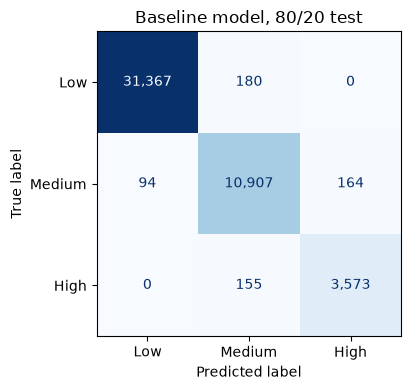

High predicted as Low: 0 | Low predicted as High: 0


In [20]:
cm = confusion_matrix(y_test, y_pred, labels=LEVELS)
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in LEVELS], columns=[f"pred {c}" for c in LEVELS])
display(cm_df)

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(cm, display_labels=LEVELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_title("Baseline model, 80/20 test")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

print("High predicted as Low:", cm[2, 0], "| Low predicted as High:", cm[0, 2])

### 3.5 Comparison models
Two variations are trained on the same split to see what matters:
* **Without class weights**, to see the effect of the imbalance handling.
* **Barangay hazard only**, which removes the hazard read at the house itself (`HouseFloodHazard*` and
  `MGBFloodSusceptibility`) and keeps only the barangay-level NOAH class.

In [21]:
HOUSE_LEVEL = ["HouseFloodHazard5yr", "HouseFloodHazard25yr", "HouseFloodHazard100yr", "MGBFloodSusceptibility"]
results = {"With class weights (baseline)": baseline}

pred = make_model(None).fit(X_train, y_train).predict(X_test)
results["Without class weights"] = metrics(y_test, pred)

pred_brgy = make_model().fit(X_train.drop(columns=HOUSE_LEVEL), y_train).predict(X_test.drop(columns=HOUSE_LEVEL))
results["Barangay hazard only"] = metrics(y_test, pred_brgy)
cm_brgy = pd.DataFrame(confusion_matrix(y_test, pred_brgy, labels=LEVELS),
                       index=[f"true {c}" for c in LEVELS], columns=[f"pred {c}" for c in LEVELS])

comparison = pd.DataFrame(results).T
comparison[["Accuracy", "BalancedAccuracy", "MacroF1", "F1_Low", "F1_Medium", "F1_High", "Recall_High"]].round(3)

,Accuracy,BalancedAccuracy,MacroF1,F1_Low,F1_Medium,F1_High,Recall_High
With class weights (baseline),0.987,0.977,0.975,0.996,0.974,0.957,0.958
Without class weights,0.988,0.974,0.977,0.996,0.975,0.960,0.950
Barangay hazard only,0.863,0.836,0.816,0.915,0.751,0.781,0.843


### 3.6 Five-fold cross-validation (grouped by household)
Set `RUN_CV = False` to skip this cell on a slow runtime (it trains five more models).

In [22]:
RUN_CV = True

cv_rows = []
if RUN_CV:
    for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
        fold_pred = make_model().fit(X.iloc[a], y.iloc[a]).predict(X.iloc[b])
        cv_rows.append({"Fold": k, **metrics(y.iloc[b], fold_pred)})
        print(f"Fold {k}: macro F1 = {cv_rows[-1]['MacroF1']:.4f}, F1 High = {cv_rows[-1]['F1_High']:.4f}")
    cv = pd.DataFrame(cv_rows).set_index("Fold")
    summary = cv.agg(["mean", "std"]).T.round(4)
    display(summary.loc[["Accuracy", "MacroF1", "F1_Low", "F1_Medium", "F1_High", "Recall_High"]])

Fold 1: macro F1 = 0.9753, F1 High = 0.9573


Fold 2: macro F1 = 0.9756, F1 High = 0.9591


Fold 3: macro F1 = 0.9782, F1 High = 0.9646


Fold 4: macro F1 = 0.9748, F1 High = 0.9579


Fold 5: macro F1 = 0.9743, F1 High = 0.9555


,mean,std
Accuracy,0.9867,0.0006
MacroF1,0.9756,0.0015
F1_Low,0.9953,0.0002
F1_Medium,0.9728,0.0013
F1_High,0.9589,0.0034
Recall_High,0.9670,0.0047


### 3.7 Which inputs the model relies on
Permutation importance: each input is shuffled in turn on a sample of test households, and the drop in macro F1 is
recorded. A large drop means the model depends on that input.

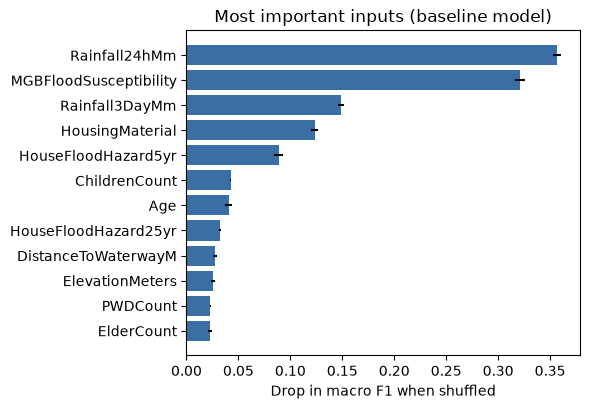

,Input,MacroF1Drop,SD
0,Rainfall24hMm,0.3566,0.0041
1,MGBFloodSusceptibility,0.3208,0.0050
2,Rainfall3DayMm,0.1488,0.0025
3,HousingMaterial,0.1233,0.0030
4,HouseFloodHazard5yr,0.0886,0.0043
5,ChildrenCount,0.0425,0.0008
6,Age,0.0405,0.0033
7,HouseFloodHazard25yr,0.0322,0.0013
8,DistanceToWaterwayM,0.0274,0.0016
9,ElevationMeters,0.0255,0.0016


In [23]:
from sklearn.inspection import permutation_importance

RUN_IMPORTANCE = True

if RUN_IMPORTANCE:
    sample = X_test.sample(10_000, random_state=0)
    imp = permutation_importance(model, sample, y_test.loc[sample.index], scoring="f1_macro",
                                 n_repeats=3, random_state=0, n_jobs=-1)
    importance = (pd.DataFrame({"Input": sample.columns, "MacroF1Drop": imp.importances_mean,
                                "SD": imp.importances_std})
                  .sort_values("MacroF1Drop", ascending=False).reset_index(drop=True))
    top = importance.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.barh(top.Input, top.MacroF1Drop, xerr=top.SD, color="#3b6ea5")
    ax.set_xlabel("Drop in macro F1 when shuffled")
    ax.set_title("Most important inputs (baseline model)")
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "feature_importance.png"), dpi=150)
    plt.show()
    display(importance.round(4).head(12))

### 3.8 Save predictions and outputs

In [24]:
import joblib

proba = model.predict_proba(X_test)
predictions = data.iloc[test_idx][["HouseholdID", "Barangay", "EventDate"]].copy()
predictions["TrueRiskLevel"] = y_test.values
predictions["PredictedRiskLevel"] = y_pred
for i, c in enumerate(model.classes_):
    predictions[f"Prob_{c}"] = proba[:, i].round(4)
predictions["Correct"] = predictions.TrueRiskLevel == predictions.PredictedRiskLevel

predictions.to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)
comparison.round(4).to_csv(os.path.join(OUT_DIR, "model_metrics_80_20.csv"), index_label="Model")
cm_df.to_csv(os.path.join(OUT_DIR, "confusion_matrix.csv"))
cm_brgy.to_csv(os.path.join(OUT_DIR, "confusion_matrix_barangay_only.csv"))
if cv_rows:
    cv.round(4).to_csv(os.path.join(OUT_DIR, "cross_validation_5fold.csv"))
if RUN_IMPORTANCE:
    importance.round(4).to_csv(os.path.join(OUT_DIR, "feature_importance.csv"), index=False)
joblib.dump({"model": model, "features": FEATURES, "categorical": CATEGORICAL,
             "categories": {c: list(X[c].cat.categories) for c in CATEGORICAL}},
            os.path.join(OUT_DIR, "baseline_model.joblib"))

print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {f:38s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:9.1f} KB")
predictions.head()

Saved files:
  baseline_model.joblib                     5924.0 KB
  confusion_matrix.csv                         0.1 KB
  confusion_matrix.png                        26.3 KB
  confusion_matrix_barangay_only.csv           0.1 KB
  cross_validation_5fold.csv                   0.7 KB
  feature_importance.csv                       0.7 KB
  feature_importance.png                      49.2 KB
  model_metrics_80_20.csv                      0.5 KB
  test_predictions.csv                      2975.9 KB


,HouseholdID,Barangay,EventDate,TrueRiskLevel,PredictedRiskLevel,Prob_High,Prob_Low,Prob_Medium,Correct
0,AGAP-SCL-00001,Gatid,1993-12-27,Medium,Medium,0.0,0.0006,0.9994,True
1,AGAP-SCL-00001,Gatid,1994-10-21,Low,Low,0.0,0.9810,0.0190,True
2,AGAP-SCL-00001,Gatid,1995-02-02,Low,Low,0.0,1.0000,0.0000,True
3,AGAP-SCL-00001,Gatid,1996-02-13,Low,Low,0.0,1.0000,0.0000,True
4,AGAP-SCL-00001,Gatid,1999-08-01,Low,Low,0.0,1.0000,0.0000,True


### 3.9 Example: predicting a single household

In [25]:
saved = joblib.load(os.path.join(OUT_DIR, "baseline_model.joblib"))
example = X_test.iloc[[0]]
print("Inputs:")
print(example.T.to_string(header=False))
print("\nPredicted :", saved["model"].predict(example)[0])
print("Actual    :", y_test.iloc[0])
print("Probabilities:", dict(zip(saved["model"].classes_, saved["model"].predict_proba(example)[0].round(3))))

Inputs:
Age                                  76
HousingMaterial                Concrete
HouseMembers                          6
ChildrenCount                         2
ElderCount                            3
PWDCount                              0
ElevationMeters                    4.33
SlopeDegrees                       1.47
DistanceToWaterwayM              1260.0
LocationType                     Inland
LandCoverType                 TreeCover
HistoricalWaterOccurrencePct        0.0
FloodHazard5yr                      Low
FloodHazard25yr                     Low
FloodHazard100yr                    Low
HouseFloodHazard5yr                None
HouseFloodHazard25yr               None
HouseFloodHazard100yr              None
MGBFloodSusceptibility         Moderate
Rainfall24hMm                     78.14
Rainfall3DayMm                    93.06
Rainfall7DayMm                    145.2

Predicted : Medium
Actual    : Medium
Probabilities: {'High': np.float64(0.0), 'Low': np.float64(0.001), 'Mediu

### 3.10 Download the outputs (Colab)

In [26]:
import shutil
archive = shutil.make_archive("AGAP_outputs", "zip", OUT_DIR)
print("Created", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Created C:\AGAP_Flood_Risk_System_Final\Activities\CSST102_Weekly_Forms\AGAP_outputs.zip


---
## Summary of Weeks 1 to 3

* **Task:** multi-class classification of household flood risk (Low / Medium / High) per rainfall event.
* **Data:** 232,110 records (7,737 households × 30 rain events, 26 barangays), 22 inputs. The raw file needed
  1,200 duplicate rows removed, 263 incomplete households dropped and 1,181 wrong labels corrected (1,225 in the raw
  file, the rest belonged to the dropped households).
* **Split:** 80/20 by household, plus 5-fold grouped cross-validation; no household is in both sets.
* **Baseline:** gradient boosting with class weights. Results are in sections 3.4 to 3.6.
* **Limitation:** the label is produced by a documented rule from official hazard maps and simulated household data,
  so the scores show that the rule is learnable. They do not prove the model predicts actual flooding.

**Next steps (Week 4 onwards):** compare other algorithms (Random Forest, Logistic Regression), study the Medium/High
errors, and look for real flood reports from the barangays or MDRRMO to check the predictions against.